# tp2 deep learning

même tâche que le tp1 (qui parle ?), même split (je relis le csv sauvegardé au tp1), mais cette fois avec des réseaux de neurones. le but c'est de comparer avec les modèles ml du tp1.

In [1]:
import re
import time
import copy
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cpu"  # les modèles sont minuscules, le cpu suffit largement (et c'est plus reproductible que mps)

In [2]:
df = pd.read_csv("data/speeches.csv")
train_df = df[df.split == "train"].reset_index(drop=True)
val_df = df[df.split == "val"].reset_index(drop=True)
test_df = df[df.split == "test"].reset_index(drop=True)
print(len(train_df), len(val_df), len(test_df))

classes = sorted(df.speaker.unique())
c2i = {c: i for i, c in enumerate(classes)}
y_tr = train_df.speaker.map(c2i).values
y_va = val_df.speaker.map(c2i).values
y_te = test_df.speaker.map(c2i).values

897 192 193


1) nettoyage et prétraitement

cette fois on tokenise nous-mêmes. je garde la ponctuation comme des tokens à part vu qu'au tp1 ça aidait (les chars avec ponctuation > mots seuls).

In [3]:
def tokeniser(t):
    return re.findall(r"[a-z']+|[!?.,;:]", t.lower())

print(tokeniser(train_df.text[0]))

tok_tr = [tokeniser(t) for t in train_df.text]
tok_va = [tokeniser(t) for t in val_df.text]
tok_te = [tokeniser(t) for t in test_df.text]

['why', ',', 'masters', ',', 'my', 'good', 'friends', ',', 'mine', 'honest', 'neighbours', ',', 'will', 'you', 'undo', 'yourselves', '?']


In [4]:
# vocab construit sur le train uniquement, les mots vus une seule fois passent en <unk>
cpt = Counter(w for toks in tok_tr for w in toks)
vocab = ["<pad>", "<unk>"] + [w for w, n in cpt.most_common() if n >= 2]
w2i = {w: i for i, w in enumerate(vocab)}
print("taille vocab :", len(vocab), "| mots vus 1 fois :", sum(1 for n in cpt.values() if n == 1))

longueurs = [len(t) for t in tok_tr]
print("longueur médiane :", np.median(longueurs), "| 95e percentile :", np.percentile(longueurs, 95))
MAX_LEN = 100  # on tronque au delà, ça touche très peu de répliques

taille vocab : 1882 | mots vus 1 fois : 2543
longueur médiane : 19.0 | 95e percentile : 128.19999999999993


In [5]:
def encoder(toks_list):
    ids = np.zeros((len(toks_list), MAX_LEN), dtype=np.int64)
    lens = np.zeros(len(toks_list), dtype=np.int64)
    for i, toks in enumerate(toks_list):
        toks = toks[:MAX_LEN] or ["<unk>"]
        ids[i, :len(toks)] = [w2i.get(w, 1) for w in toks]
        lens[i] = len(toks)
    return torch.tensor(ids), torch.tensor(lens)

X_tr, L_tr = encoder(tok_tr)
X_va, L_va = encoder(tok_va)
X_te, L_te = encoder(tok_te)
print(X_tr.shape)
print("taux de <unk> sur la val :", round((X_va == 1).sum().item() / L_va.sum().item(), 3))

torch.Size([897, 100])
taux de <unk> sur la val : 0.111


2) représentation

trois façons de représenter le texte pour le réseau :
- le tf-idf de caractères du tp1, donné à un mlp (même représentation, modèle non linéaire)
- des embeddings appris, moyennés sur la réplique (genre fasttext, l'ordre est perdu)
- des embeddings appris passés dans un gru bidirectionnel (là l'ordre compte)

In [6]:
tfidf_c = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
T_tr = torch.tensor(tfidf_c.fit_transform(train_df.low).toarray(), dtype=torch.float32)
T_va = torch.tensor(tfidf_c.transform(val_df.low).toarray(), dtype=torch.float32)
T_te = torch.tensor(tfidf_c.transform(test_df.low).toarray(), dtype=torch.float32)
print(T_tr.shape)

torch.Size([897, 18680])


In [7]:
class MLP(nn.Module):
    def __init__(self, d_in, d_h, n_cls, p=0.5):
        super().__init__()
        self.net = nn.Sequential(nn.Dropout(0.2), nn.Linear(d_in, d_h), nn.ReLU(), nn.Dropout(p), nn.Linear(d_h, n_cls))

    def forward(self, x, lens=None):
        return self.net(x)


class MoyenneEmb(nn.Module):
    def __init__(self, n_vocab, d, n_cls, p=0.5):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, d, padding_idx=0)
        self.drop = nn.Dropout(p)
        self.out = nn.Linear(d, n_cls)

    def forward(self, x, lens):
        e = self.emb(x)                              # (b, t, d)
        masque = (x != 0).unsqueeze(-1).float()
        moy = (e * masque).sum(1) / lens.unsqueeze(1).float()   # moyenne sans compter le padding
        return self.out(self.drop(moy))


class BiGRU(nn.Module):
    def __init__(self, n_vocab, d, h, n_cls, p=0.5):
        super().__init__()
        self.emb = nn.Embedding(n_vocab, d, padding_idx=0)
        self.gru = nn.GRU(d, h, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(p)
        self.out = nn.Linear(2 * h, n_cls)

    def forward(self, x, lens):
        e = self.drop(self.emb(x))
        packed = pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False)
        _, hn = self.gru(packed)                     # hn : (2, b, h), dernier état de chaque sens
        hcat = torch.cat([hn[0], hn[1]], dim=1)
        return self.out(self.drop(hcat))

3) entraînement

loss = entropie croisée pondérée par classe (poids n / (k * n_c) comme dans le cours) pour compenser le déséquilibre, adam, weight decay, et early stopping sur le f1 macro de la val.

In [8]:
n_c = np.bincount(y_tr, minlength=len(classes))
poids = torch.tensor(len(y_tr) / (len(classes) * n_c), dtype=torch.float32)
print(dict(zip([c.lower() for c in classes], poids.numpy().round(2))))


def predire(model, X, L, bs=256):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            out.append(model(X[i:i + bs], L[i:i + bs]))
    return torch.cat(out)


def f1m(y, p):
    return precision_recall_fscore_support(y, p, average="macro", zero_division=0)[2]


def entrainer(model, X, L, y, Xv, Lv, yv, epochs=60, lr=1e-3, wd=1e-4, bs=32, patience=8):
    torch.manual_seed(SEED)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    crit = nn.CrossEntropyLoss(weight=poids)
    yt, yvt = torch.tensor(y), torch.tensor(yv)
    hist = {"loss_tr": [], "loss_va": [], "f1_tr": [], "f1_va": []}
    best, best_state, attente = -1, None, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(X))
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = crit(model(X[idx], L[idx]), yt[idx])
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)  # surtout utile pour le gru
            opt.step()
        lo_tr, lo_va = predire(model, X, L), predire(model, Xv, Lv)
        hist["loss_tr"].append(crit(lo_tr, yt).item())
        hist["loss_va"].append(crit(lo_va, yvt).item())
        hist["f1_tr"].append(f1m(y, lo_tr.argmax(1).numpy()))
        hist["f1_va"].append(f1m(yv, lo_va.argmax(1).numpy()))
        if hist["f1_va"][-1] > best:
            best, best_state, attente = hist["f1_va"][-1], copy.deepcopy(model.state_dict()), 0
        else:
            attente += 1
            if attente >= patience:
                break
    model.load_state_dict(best_state)
    print(f"arrêt à l'epoch {ep + 1}, meilleur f1 val = {best:.3f}")
    return hist

{'coriolanus': np.float32(1.09), 'duke vincentio': np.float32(0.85), 'gloucester': np.float32(0.76), 'isabella': np.float32(1.27), 'king richard iii': np.float32(1.18), 'menenius': np.float32(0.99), 'petruchio': np.float32(1.05), 'romeo': np.float32(1.0)}


In [9]:
config = {
    "mlp tfidf": (lambda: MLP(T_tr.shape[1], 256, len(classes)), (T_tr, L_tr), (T_va, L_va), (T_te, L_te), dict(lr=1e-3, wd=1e-4)),
    "moyenne emb": (lambda: MoyenneEmb(len(vocab), 64, len(classes)), (X_tr, L_tr), (X_va, L_va), (X_te, L_te), dict(lr=5e-3, wd=1e-5)),
    "bigru": (lambda: BiGRU(len(vocab), 64, 64, len(classes)), (X_tr, L_tr), (X_va, L_va), (X_te, L_te), dict(lr=2e-3, wd=1e-5)),
}

modeles, historiques, temps = {}, {}, {}
for nom, (fabrique, tr, va, te, hp) in config.items():
    print("==", nom)
    torch.manual_seed(SEED)
    m = fabrique()
    print("paramètres :", sum(p.numel() for p in m.parameters()))
    t0 = time.time()
    historiques[nom] = entrainer(m, *tr, y_tr, *va, y_va, **hp)
    temps[nom] = time.time() - t0
    modeles[nom] = m

== mlp tfidf


paramètres : 4784392


arrêt à l'epoch 23, meilleur f1 val = 0.521
== moyenne emb
paramètres : 120968


arrêt à l'epoch 58, meilleur f1 val = 0.423
== bigru
paramètres : 171400


arrêt à l'epoch 32, meilleur f1 val = 0.312


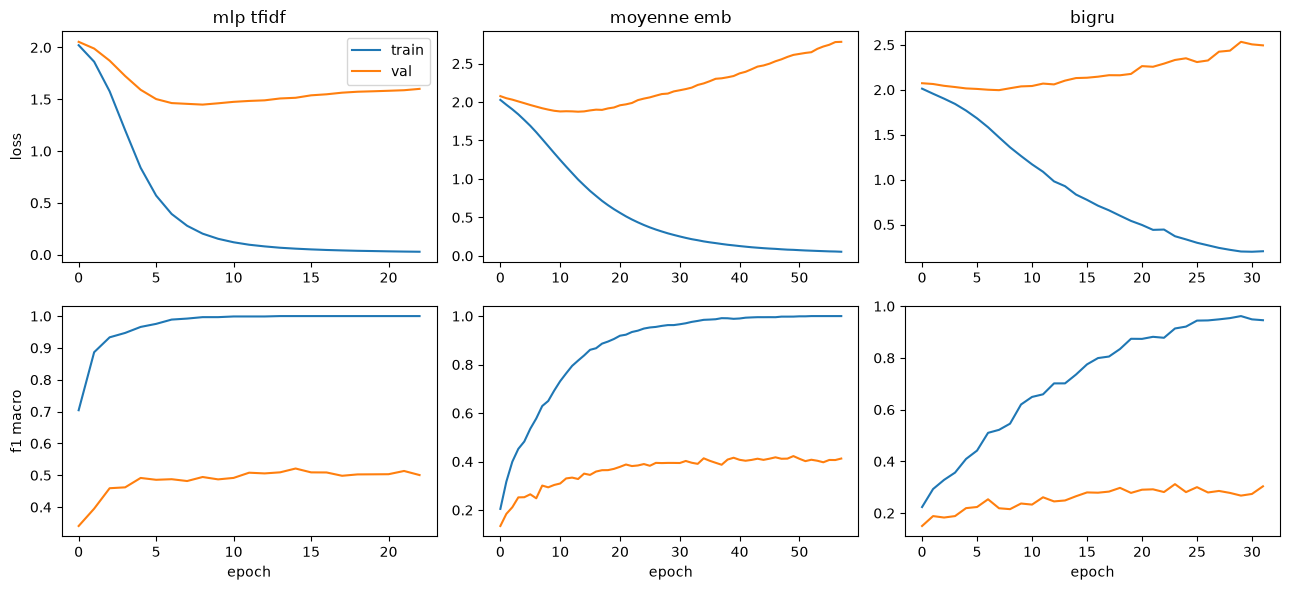

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, (nom, h) in enumerate(historiques.items()):
    axes[0, j].plot(h["loss_tr"], label="train")
    axes[0, j].plot(h["loss_va"], label="val")
    axes[0, j].set_title(nom)
    axes[1, j].plot(h["f1_tr"], label="train")
    axes[1, j].plot(h["f1_va"], label="val")
    axes[1, j].set_xlabel("epoch")
axes[0, 0].set_ylabel("loss")
axes[1, 0].set_ylabel("f1 macro")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

on voit bien le sur-apprentissage : le train monte quasi à 1 alors que la val plafonne vite. normal avec ~900 exemples d'entraînement. l'early stopping récupère les poids au meilleur moment de la val.

In [11]:
# je teste vite fait un peu plus de dropout / de régularisation sur le gru pour voir si ça aide
for p, wd in [(0.3, 1e-5), (0.6, 1e-4), (0.7, 1e-3)]:
    torch.manual_seed(SEED)
    m = BiGRU(len(vocab), 64, 64, len(classes), p=p)
    print(f"dropout {p}, wd {wd} :", end=" ")
    entrainer(m, X_tr, L_tr, y_tr, X_va, L_va, y_va, lr=2e-3, wd=wd)

dropout 0.3, wd 1e-05 : 

arrêt à l'epoch 24, meilleur f1 val = 0.277
dropout 0.6, wd 0.0001 : 

arrêt à l'epoch 25, meilleur f1 val = 0.255
dropout 0.7, wd 0.001 : 

arrêt à l'epoch 23, meilleur f1 val = 0.282


4) évaluation et comparaison ml / dl

pour que la comparaison soit honnête tout le monde est entraîné sur le train seul et réglé sur la val (au tp1 j'avais refit sur train+val, donc les chiffres ml ici sont un poil différents).

In [12]:
ml = {
    "svm tfidf chars (tp1)": make_pipeline(
        ColumnTransformer([("c", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), "low")]),
        LinearSVC(C=1, class_weight="balanced")),
    "naive bayes (tp1)": make_pipeline(
        ColumnTransformer([
            ("m", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "clean"),
            ("c", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), "low")]),
        ComplementNB(alpha=0.3)),
}

preds = {}
for nom, pipe in ml.items():
    t0 = time.time()
    pipe.fit(train_df, train_df.speaker)
    temps[nom] = time.time() - t0
    preds[nom] = pipe.predict(test_df)

for nom, (_, _, _, te, _) in config.items():
    preds[nom] = np.array(classes)[predire(modeles[nom], *te).argmax(1).numpy()]

lignes = []
for nom, p in preds.items():
    pm, rm, fm, _ = precision_recall_fscore_support(test_df.speaker, p, average="macro", zero_division=0)
    lignes.append({"modele": nom, "type": "ml" if "tp1" in nom else "dl",
                   "accuracy": accuracy_score(test_df.speaker, p), "precision_macro": pm,
                   "rappel_macro": rm, "f1_macro": fm, "temps_fit_s": temps[nom]})
comp = pd.DataFrame(lignes).set_index("modele").sort_values("f1_macro", ascending=False)
comp.round(3)

,type,accuracy,precision_macro,rappel_macro,f1_macro,temps_fit_s
modele,,,,,,
mlp tfidf,dl,0.477,0.473,0.470,0.470,5.047
naive bayes (tp1),ml,0.482,0.471,0.467,0.465,0.141
svm tfidf chars (tp1),ml,0.446,0.439,0.438,0.436,0.223
moyenne emb,dl,0.394,0.402,0.382,0.380,1.302
bigru,dl,0.306,0.301,0.299,0.287,24.594


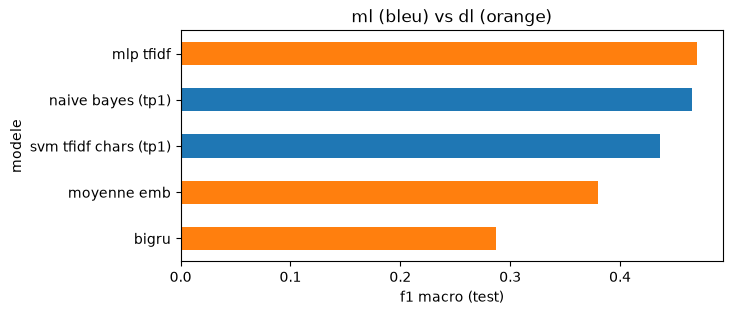

In [13]:
comp.f1_macro.plot.barh(color=["tab:blue" if t == "ml" else "tab:orange" for t in comp.type], figsize=(7, 3))
plt.xlabel("f1 macro (test)")
plt.gca().invert_yaxis()
plt.title("ml (bleu) vs dl (orange)")
plt.show()

In [14]:
meilleur_dl = comp[comp.type == "dl"].index[0]
print(meilleur_dl)
print(classification_report(test_df.speaker, preds[meilleur_dl], zero_division=0))

mlp tfidf
                  precision    recall  f1-score   support

      CORIOLANUS       0.40      0.45      0.43        22
  DUKE VINCENTIO       0.52      0.59      0.55        29
      GLOUCESTER       0.53      0.50      0.52        32
        ISABELLA       0.40      0.42      0.41        19
KING RICHARD III       0.40      0.40      0.40        20
        MENENIUS       0.50      0.42      0.45        24
       PETRUCHIO       0.62      0.57      0.59        23
           ROMEO       0.42      0.42      0.42        24

        accuracy                           0.48       193
       macro avg       0.47      0.47      0.47       193
    weighted avg       0.48      0.48      0.48       193



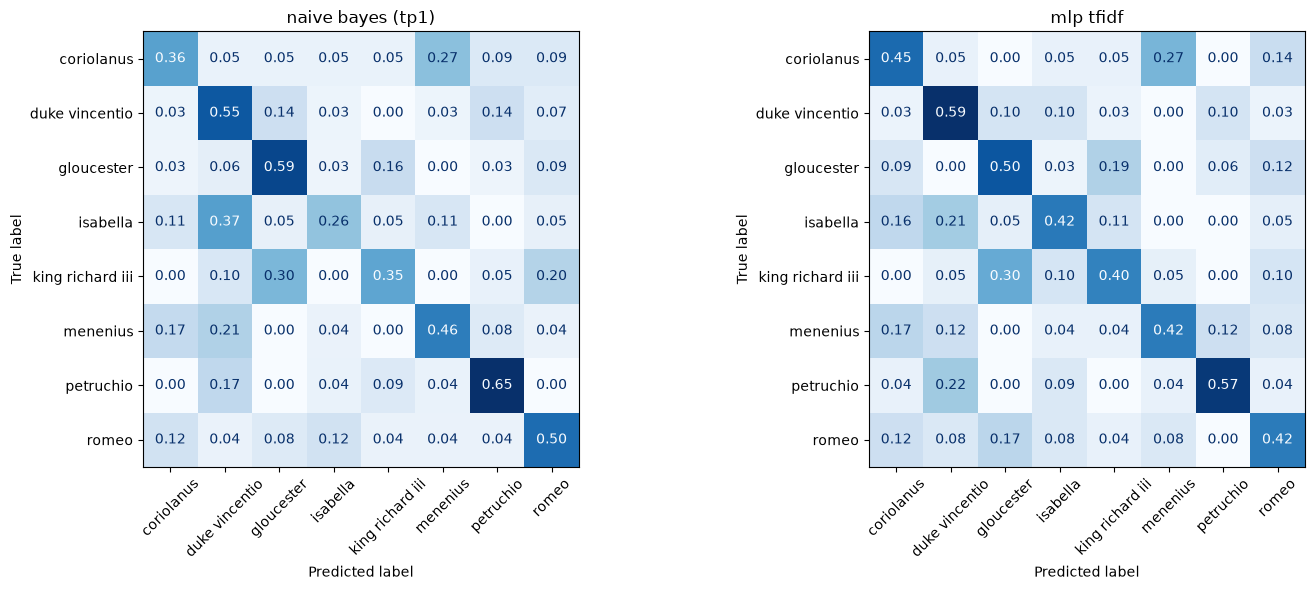

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, nom in zip(axes, [comp[comp.type == "ml"].index[0], meilleur_dl]):
    cm = confusion_matrix(test_df.speaker, preds[nom], labels=classes, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=[c.lower() for c in classes]).plot(
        ax=ax, cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=45)
    ax.set_title(nom)
plt.tight_layout()
plt.show()

In [16]:
# par curiosité : est-ce que les embeddings appris ont un sens ? voisins les plus proches (cosinus)
E = modeles["moyenne emb"].emb.weight.detach()
E = E / E.norm(dim=1, keepdim=True).clamp(min=1e-8)
for w in ["kate", "love", "rome", "brother", "king", "thou"]:
    sims = E @ E[w2i[w]]
    voisins = [vocab[i] for i in sims.argsort(descending=True)[1:7].tolist()]
    print(f"{w:8s} -> {voisins}")

kate     -> ['lands', 'obedient', 'habit', 'instruct', 'wager', 'verona']
love     -> ['paper', 'mis', 'chaos', 'vanity', 'inquire', 'mercutio']
rome     -> ['ladies', 'perceive', 'consuls', 'doit', 'corioli', 'custom']
brother  -> ['stern', 'minds', 'top', 'humbly', 'middle', 'tricks']
king     -> ['england', 'instead', 'issue', 'drops', 'stop', 'herself']
thou     -> ['paper', 'philosophy', 'shadows', 'stands', 'black', 'courtesy']


bilan : le seul réseau qui tient la route c'est le mlp sur le tf-idf de caractères, il arrive au niveau des modèles ml (f1 macro ~0.47) mais avec ~4.8m de paramètres et beaucoup plus de temps d'entraînement, pour le même résultat. les modèles qui apprennent leurs propres embeddings font nettement moins bien, surtout le bigru (~0.29) : avec 900 répliques il n'y a pas assez de données pour apprendre à la fois les embeddings et la récurrence, en plus 11% des tokens de val sont des <unk>. et le réglage du dropout n'y change rien.

les voisins dans l'espace d'embedding ont quand même un peu de sens (kate -> obedient, wager, verona / rome -> consuls, corioli), en gros ils apprennent surtout à reconnaître la pièce.

à noter aussi que le svm passe de 0.48 (tp1, entraîné sur train+val) à 0.44 ici (train seul) : avec si peu de données les scores bougent pas mal, il faut rester prudent sur les petits écarts. conclusion, sur peu de données une baseline linéaire tf-idf est dure à battre, le dl deviendrait intéressant avec beaucoup plus de texte ou des embeddings pré-entraînés.